In [9]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
import urllib.request
from google.colab import files
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

In [3]:
os.makedirs('model/face', exist_ok=True)

print("Upload YuNet Model (face_detection_yunet_2022mar.onnx)")
uploaded_model =files.upload()

for filename in uploaded_model.keys():
  dest_model = os.path.join('model/face', filename)
  os.rename(filename, dest_model)
  print(f"Renamed {filename} To {dest_model}")

Upload YuNet Model (face_detection_yunet_2022mar.onnx)


Saving face_detection_yunet_2022mar.onnx to face_detection_yunet_2022mar.onnx
Renamed face_detection_yunet_2022mar.onnx To model/face/face_detection_yunet_2022mar.onnx


In [2]:
os.makedirs('images', exist_ok=True)

print("Upload Test Images (e.g., akhavan.jpg, largest-selfie.jpg)")
uploaded_images = files.upload()

for filename in uploaded_images.keys():
 dest_images = os.path.join('images', filename)
 os.rename(filename, dest_images)
 print(f"Renamed {filename} To {dest_images}")

Upload Test Images (e.g., akhavan.jpg, largest-selfie.jpg)


Saving akhavan.jpg to akhavan.jpg
Saving largest-selfie.jpg to largest-selfie.jpg
Renamed akhavan.jpg To images/akhavan.jpg
Renamed largest-selfie.jpg To images/largest-selfie.jpg


Model Loaded Successfully!


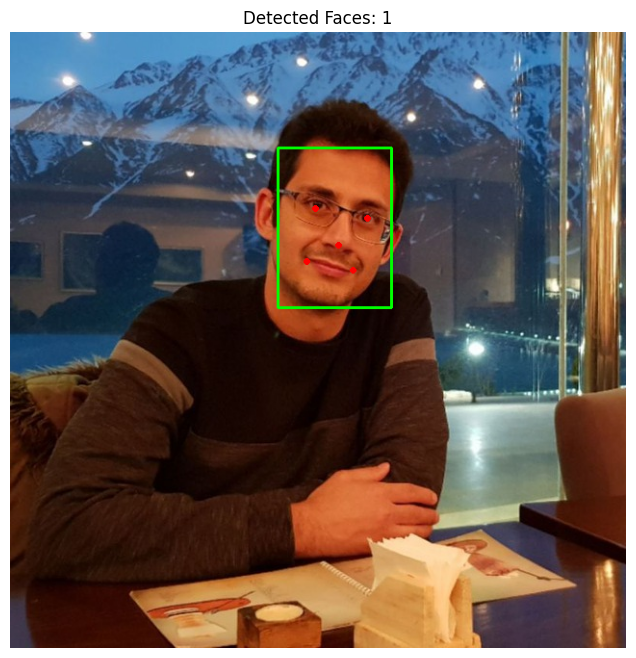

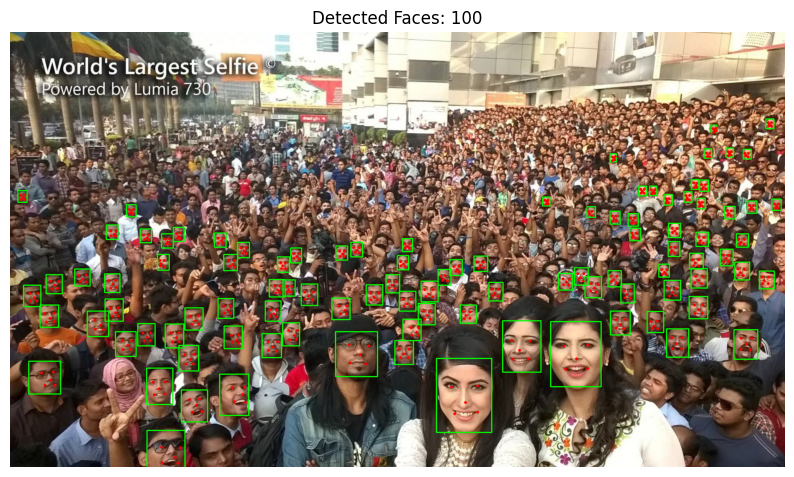

In [10]:
model_path = 'model/face/face_detection_yunet_2023mar.onnx'
os.makedirs('model/face', exist_ok=True)

if not os.path.exists(model_path):
  print("Downloading Compatible YuNet Model...")
  url = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
  urllib.request.urlretrieve(url, model_path)

try:
  model = cv2.FaceDetectorYN_create(model_path, "", (320, 320), 0.9, 0.3, 5000)
  print("Model Loaded Successfully!")
except Exception as e:
  print(f"Error Loading Model: {e}")

image_dir = 'images'
image_files = [f for f in os.listdir(image_dir) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]

for image_file in image_files:
  image_path = os.path.join(image_dir, image_file)
  image = cv2.imread(image_path)
  if image is None:
    continue

  h, w, _ = image.shape
  model.setInputSize((w, h))

  _, faces = model.detect(image)

  if faces is not None:
    for face in faces:
      coords = face[:-1].astype(np.int32)
      cv2.rectangle(image, (coords[0], coords[1]), (coords[0] + coords[2], coords[1] + coords[3]), (0, 255, 0), 2)

      for i in range(4, 14, 2):
        cv2.circle(image, (coords[i], coords[i + 1]), 2, (0, 0, 255), 2)

  plt.figure(figsize=(10, 8))

  plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
  count = len(faces) if faces is not None else 0
  plt.title(f'Detected Faces: {count}')
  plt.axis('off')

  plt.show()

<IPython.core.display.Javascript object>

Saved To webcam_face.jpg


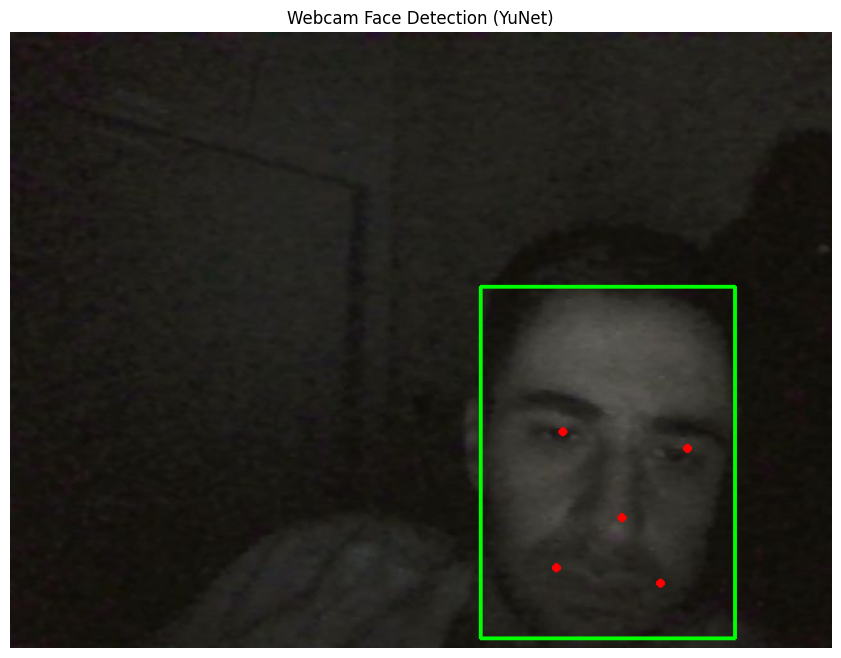

In [14]:
def take_photo(filename='webcam_face.jpg', quality=0.8):
    js = Javascript('''
        async function takePhoto(quality) {
            const div = document.createElement('div');
            const capture = document.createElement('button');
            capture.textContent = 'Capture';
            div.appendChild(capture);
            const video = document.createElement('video');
            video.style.display = 'block';
            const stream = await navigator.mediaDevices.getUserMedia({video: true});
            document.body.appendChild(div);
            div.appendChild(video);
            video.srcObject = stream;
            await video.play();
            google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
            await new Promise((resolve) => capture.onclick = resolve);
            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);
            stream.getVideoTracks()[0].stop();
            div.remove();
            return canvas.toDataURL('image/jpeg', quality);
        }
    ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

try:
    filename = take_photo('webcam_face.jpg')
    print(f'Saved To {filename}')

    frame = cv2.imread(filename)
    h, w, _ = frame.shape

    detector = cv2.FaceDetectorYN_create(model_path, "", (320, 320), 0.9, 0.3, 5000)
    detector.setInputSize((w, h))
    _, faces = detector.detect(frame)

    if faces is not None:
      for face in faces:
        coords = face[:-1].astype(np.int32)
        cv2.rectangle(frame, (coords[0], coords[1]), (coords[0] + coords[2], coords[1] + coords[3]), (0, 255, 0), 2)

        for i in range(4, 14, 2):
          cv2.circle(frame, (coords[i], coords[i + 1]), 2, (0, 0, 255), 2)

    plt.figure(figsize=(12, 8))

    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title('Webcam Face Detection (YuNet)')
    plt.axis('off')

    plt.show()

except Exception as err:
  print(str(err))